<a href="https://colab.research.google.com/github/Le2se0hy/XAI_An/blob/main/0825_olsslr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

- **해당 연도 행 수 `no_all <= 30000`**
  1. 동일 위도·경도 좌표를 하나로 통합
  2. 동일 좌표 거래가격의 평균 계산
  3. 유일 좌표끼리 Haversine 거리 계산
  4. 1 km 이내이면 `1 / 거리`, 그 외 0
  5. 행 합으로 나누어 행 표준화
  6. 유일 좌표 평균가격에 W를 곱해 공간지연값 생성
  7. 그 값을 원래 거래행에 다시 배정

- **해당 연도 행 수 `no_all > 30000`**
  1. 동일 좌표를 통합하지 않고 원래 거래행 전체 사용
  2. 각 거래행을 기준으로 다른 모든 거래행과 Haversine 거리 계산
  3. 자기 자신 또는 거리 0인 행은 0
  4. 1 km 이내이면 `1 / 거리`, 그 외 0
  5. 각 행을 바로 행 표준화
  6. 표준화된 한 행과 원래 `Y`를 곱해 공간지연값 생성

그 후 MATLAB과 같은 방식으로 `rho=-0.99`부터 `0.99`까지 0.01 간격으로 탐색하고,
`Y_splag = Y - rho * IND_spw`의 OLS RMSE가 가장 작은 rho를 선택합니다.

**BallTree는 사용하지 않습니다.**

> Python에서는 MATLAB의 이중 `for`문과 동일한 거리·가중치 수식을 NumPy 벡터연산으로 계산합니다.
> 구현 방식만 벡터화했으며, 공간가중치의 정의와 분기 기준은 MATLAB 코드와 같습니다.


## 1. 필요한 패키지 설치


In [ ]:
!pip install -q pandas numpy scipy statsmodels openpyxl matplotlib


## 2. 라이브러리 및 Google Drive 연결


In [ ]:
from __future__ import annotations

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from scipy import sparse
import statsmodels.api as sm
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

print("Google Drive 연결 완료")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive 연결 완료


In [ ]:
FILE_PATH = Path("/content/drive/MyDrive/비교/0912.xlsx")



## 3. 사용자 설정


In [ ]:
# ============================================================
# 입력·출력 경로
# ============================================================

FILE_PATH = Path("/content/drive/MyDrive/비교/0912.xlsx")
OUTPUT_DIR = Path("/content/drive/MyDrive/0911_비교용/0913_Slr까지돌렸을때.xlsx")

COLAB_UPLOAD_PATH = Path("/content/0913_Slr까지돌렸을때.xlsx")

# ============================================================
# 분석 설정
# ============================================================

YEARS = [2022, 2023, 2024, 2025]

DISTANCE_BAND_KM = 1.0
RHO_VALUES = np.round(np.arange(-0.99, 1.00, 0.01), 2)
EARTH_RADIUS_KM = 6371.0
MATLAB_BRANCH_THRESHOLD = 30000

YEAR_COL = "year"
TARGET_COL = "log price"
LAT_COL = "Latitude"
LON_COL = "Longitude"

FEATURE_COLS = [
    "size",
    "floor",
    "unit",
    "construction",
    "parking per unit",
    "heating",
    "max floor",
    "dist water",
    "dist green",
    "dist subway",
    "dist office",
    "highschool",
    "bus stop",
    "academy",
    "population",
    "median",
    "young",
    "sex ratio",
    "density",
    "spring",
    "fall",
    "winter"
]

if FILE_PATH.exists():
    input_file = FILE_PATH
elif COLAB_UPLOAD_PATH.exists():
    input_file = COLAB_UPLOAD_PATH
else:
    raise FileNotFoundError(
        "Excel 파일을 찾을 수 없습니다.\n"
        f"Google Drive 경로: {FILE_PATH}\n"
        f"Colab 업로드 경로: {COLAB_UPLOAD_PATH}\n"
        "파일 위치에 맞게 FILE_PATH를 수정하세요."
    )

print("입력 파일:", input_file)
print("결과 폴더:", OUTPUT_DIR)
print("분석 연도:", YEARS)
print("MATLAB 분기 기준:", MATLAB_BRANCH_THRESHOLD)
print("거리 기준:", DISTANCE_BAND_KM, "km")


입력 파일: /content/drive/MyDrive/비교/0912.xlsx
결과 폴더: /content/drive/MyDrive/0911_비교용/0913_Slr까지돌렸을때.xlsx
분석 연도: [2022, 2023, 2024, 2025]
MATLAB 분기 기준: 30000
거리 기준: 1.0 km


## 4. MATLAB `lldistkm.m`과 같은 Haversine 거리 함수


In [ ]:
def lldistkm(latlon1, latlon2):
    """
    MATLAB lldistkm.m 계산식 그대로.
    d1km: Haversine distance
    d2km: Pythagorean/equirectangular approximation
    """
    lat1 = float(latlon1[0]) * np.pi / 180.0
    lat2 = float(latlon2[0]) * np.pi / 180.0
    lon1 = float(latlon1[1]) * np.pi / 180.0
    lon2 = float(latlon2[1]) * np.pi / 180.0

    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1

    a = (
        np.sin(delta_lat / 2.0) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(delta_lon / 2.0) ** 2
    )
    c = 2.0 * np.arctan2(np.sqrt(a), np.sqrt(1.0 - a))
    d1km = EARTH_RADIUS_KM * c

    x = delta_lon * np.cos((lat1 + lat2) / 2.0)
    y = delta_lat
    d2km = EARTH_RADIUS_KM * np.sqrt(x * x + y * y)

    return float(d1km), float(d2km)


def haversine_from_one_to_many_km(lat1_deg, lon1_deg, lat2_deg, lon2_deg):
    """
    lldistkm.m의 d1km 식을 한 기준점에서 여러 비교점으로 벡터화.
    """
    lat1 = lat1_deg * np.pi / 180.0
    lon1 = lon1_deg * np.pi / 180.0
    lat2 = np.asarray(lat2_deg, dtype=float) * np.pi / 180.0
    lon2 = np.asarray(lon2_deg, dtype=float) * np.pi / 180.0

    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1

    a = (
        np.sin(delta_lat / 2.0) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(delta_lon / 2.0) ** 2
    )
    c = 2.0 * np.arctan2(np.sqrt(a), np.sqrt(1.0 - a))

    return EARTH_RADIUS_KM * c


## 5. 데이터 불러오기 및 점검


In [ ]:
def load_and_validate_data(file_path):
    df = pd.read_excel(file_path, sheet_name=0)
    df.columns = df.columns.astype(str).str.strip()

    required_cols = [YEAR_COL, TARGET_COL, LAT_COL, LON_COL] + FEATURE_COLS
    missing_cols = [col for col in required_cols if col not in df.columns]

    if missing_cols:
        raise KeyError(f"Excel에 다음 필수 열이 없습니다: {missing_cols}")

    for col in required_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    bad = df[required_cols].isna().any(axis=1)
    if bad.any():
        bad_count = int(bad.sum())
        raise ValueError(
            f"필수 열에 결측치 또는 숫자로 변환되지 않는 값이 {bad_count:,}개 행에 있습니다. "
            "MATLAB 원본과 동일한 분석대상을 유지하기 위해 자동 삭제하지 않았습니다."
        )

    df[YEAR_COL] = df[YEAR_COL].astype(int)

    print(f"전체 행 수: {len(df):,}")
    print("\n연도별 행 수:")
    print(
        df[df[YEAR_COL].isin(YEARS)][YEAR_COL]
        .value_counts()
        .sort_index()
        .to_string()
    )

    return df.reset_index(drop=True)


df_all = load_and_validate_data(input_file)
display(df_all.head())


전체 행 수: 188,853

연도별 행 수:
year
2022    12535
2023    35403
2024    57482
2025    83433


,year,month,day,District,Dong,Jibun,Apartment_Name,Full_Address,Base_Address,size,...,matched_office_name,spring,fall,winter,population,sex ratio,density,young,median,Old Population
0,2022,2,21,동대문구,용두동,235-30,서안팰리스,서울특별시 동대문구 용두동 235-30 서안팰리스,서울특별시 동대문구 용두동 235-30,81.85,...,동대문구청,0,0,1,32355,100.402601,20096.273292,6.394684,75.771905,17.833411
1,2025,9,8,동대문구,용두동,235-30,서안팰리스,서울특별시 동대문구 용두동 235-30 서안팰리스,서울특별시 동대문구 용두동 235-30,75.07,...,동대문구청,0,1,0,22462,97.000526,29555.263158,6.513222,72.825216,20.661562
2,2024,6,19,마포구,도화동,559,마포트라팰리스,서울특별시 마포구 도화동 559 마포트라팰리스,서울특별시 마포구 도화동 559,84.02,...,마포구청,0,0,0,78249,88.252418,31679.757085,9.923450,72.670577,17.405973
3,2024,7,28,마포구,도화동,559,마포트라팰리스,서울특별시 마포구 도화동 559 마포트라팰리스,서울특별시 마포구 도화동 559,84.02,...,마포구청,0,0,0,78216,88.154919,31666.396761,9.916130,72.651376,17.432495
4,2024,8,30,마포구,도화동,559,마포트라팰리스,서울특별시 마포구 도화동 559 마포트라팰리스,서울특별시 마포구 도화동 559,75.36,...,마포구청,0,0,0,78181,88.002886,31652.226721,9.902662,72.602039,17.495299


## 6. MATLAB 분기 1: `no_all <= 30000`


In [ ]:
def spatial_lag_matlab_branch_small(df, distance_band_km):
    """
    MATLAB Code.m의 no_all <= 30000 분기 재현.
    BallTree는 사용하지 않습니다.
    """
    lat = df[LAT_COL].to_numpy(dtype=float)
    lon = df[LON_COL].to_numpy(dtype=float)

    n_all = len(df)

    # MATLAB unique(location_data(:,1:2),'rows') + 동일 위치 가격 평균
    unique_locations = (
        df.groupby([LAT_COL, LON_COL], sort=True, as_index=False)[TARGET_COL]
        .mean()
        .rename(columns={TARGET_COL: "Mean_Price"})
    )

    lat_uni = unique_locations[LAT_COL].to_numpy(dtype=float)
    lon_uni = unique_locations[LON_COL].to_numpy(dtype=float)
    y_uni = unique_locations["Mean_Price"].to_numpy(dtype=float)
    n_uni = len(unique_locations)

    print("MATLAB 분기: no_all <= 30000")
    print(f"no_all = {n_all:,}")
    print(f"no_uni = {n_uni:,}")

    row_parts = []
    col_parts = []
    data_parts = []
    wy_unique = np.zeros(n_uni, dtype=float)

    all_uni_idx = np.arange(n_uni)

    for i in range(n_uni):
        d1km = haversine_from_one_to_many_km(
            lat_uni[i],
            lon_uni[i],
            lat_uni,
            lon_uni,
        )

        # MATLAB:
        # if i==j -> 0
        # elseif d1km<=distance_band -> 1/d1km
        valid = (all_uni_idx != i) & (d1km <= distance_band_km)
        idx = np.flatnonzero(valid)

        if idx.size == 0:
            continue

        raw_weights = 1.0 / d1km[idx]
        sumrow = raw_weights.sum()

        if sumrow == 0:
            sumrow = 1.0

        std_weights = raw_weights / sumrow

        row_parts.append(np.full(idx.size, i, dtype=np.int64))
        col_parts.append(idx.astype(np.int64, copy=False))
        data_parts.append(std_weights)

        wy_unique[i] = std_weights @ y_uni[idx]

    if row_parts:
        rows = np.concatenate(row_parts)
        cols = np.concatenate(col_parts)
        values = np.concatenate(data_parts)
    else:
        rows = np.array([], dtype=np.int64)
        cols = np.array([], dtype=np.int64)
        values = np.array([], dtype=float)

    # MATLAB dense spwmat_rowsum과 동일한 값을 sparse 형식으로 저장
    w_rowsum = sparse.csr_matrix(
        (values, (rows, cols)),
        shape=(n_uni, n_uni),
        dtype=float,
    )

    unique_locations["Spatial_Lag_Price"] = wy_unique

    # IND_spw_uni의 값을 원래 거래행으로 재배정
    mapped = df[[LAT_COL, LON_COL]].merge(
        unique_locations[[LAT_COL, LON_COL, "Spatial_Lag_Price"]],
        on=[LAT_COL, LON_COL],
        how="left",
        sort=False,
        validate="many_to_one",
    )

    wy_all = mapped["Spatial_Lag_Price"].to_numpy(dtype=float)

    return {
        "branch": "no_all<=30000",
        "unique_locations": unique_locations,
        "w_matrix": w_rowsum,
        "wy_all": wy_all,
        "wy_unique": wy_unique,
    }


## 7. MATLAB 분기 2: `no_all > 30000`


In [ ]:
def spatial_lag_matlab_branch_large(df, distance_band_km):
    """
    MATLAB Code.m의 no_all > 30000 분기 재현.

    MATLAB의 j 반복만 NumPy 벡터연산으로 바꾸고,
    각 i행의 거리식, 0거리 제외, 1/거리 가중치,
    행 표준화, W행*Y 계산은 동일합니다.
    """
    y = df[TARGET_COL].to_numpy(dtype=float)
    lat = df[LAT_COL].to_numpy(dtype=float)
    lon = df[LON_COL].to_numpy(dtype=float)

    n_all = len(df)
    wy_all = np.zeros(n_all, dtype=float)
    all_idx = np.arange(n_all)

    print("MATLAB 분기: no_all > 30000")
    print(f"no_all = {n_all:,}")
    print("원자료 거래행 전체를 그대로 사용합니다.")

    for i in range(n_all):
        d1km = haversine_from_one_to_many_km(
            lat[i],
            lon[i],
            lat,
            lon,
        )

        # MATLAB: if i==j || d1km==0 -> 0
        valid = (
            (all_idx != i)
            & (d1km != 0.0)
            & (d1km <= distance_band_km)
        )

        idx = np.flatnonzero(valid)

        if idx.size == 0:
            wy_all[i] = 0.0
            continue

        raw_weights = 1.0 / d1km[idx]
        sumrow = raw_weights.sum()

        if sumrow == 0:
            sumrow = 1.0

        std_weights = raw_weights / sumrow

        # MATLAB: IND_spw(i)=spwmat_rowsum*Y
        wy_all[i] = std_weights @ y[idx]

    return {
        "branch": "no_all>30000",
        "unique_locations": None,
        "w_matrix": None,
        "wy_all": wy_all,
        "wy_unique": None,
    }


## 8. MATLAB의 30,000 기준 분기


In [ ]:
def build_spatial_lag_matlab_logic(df, distance_band_km=1.0):
    n_all = len(df)

    if n_all <= MATLAB_BRANCH_THRESHOLD:
        return spatial_lag_matlab_branch_small(
            df=df,
            distance_band_km=distance_band_km,
        )
    else:
        return spatial_lag_matlab_branch_large(
            df=df,
            distance_band_km=distance_band_km,
        )


## 9. MATLAB `fitlm` 방식 OLS 및 rho 탐색


In [ ]:
def fit_ols(y, x_df):
    x_with_const = sm.add_constant(x_df.astype(float), has_constant="add")
    return sm.OLS(y.astype(float), x_with_const).fit()


def residual_rmse_matlab_style(model):
    return float(np.sqrt(model.mse_resid))


def search_best_rho(y, wy, x_df, rho_values):
    best_model = None
    best_rho = None
    best_rmse = None
    best_y_splag = None

    records = []

    for k, rho in enumerate(rho_values):
        y_splag = y - rho * wy
        model = fit_ols(y_splag, x_df)
        rmse = residual_rmse_matlab_style(model)

        records.append({
            "rho": float(rho),
            "RMSE": rmse,
        })

        # MATLAB은 첫 rho=-0.99를 기준값으로 두고,
        # 이후 RMSE가 더 작을 때만 교체
        if k == 0 or rmse < best_rmse:
            best_model = model
            best_rho = float(rho)
            best_rmse = rmse
            best_y_splag = y_splag.copy()

    return (
        best_rho,
        best_rmse,
        best_model,
        best_y_splag,
        pd.DataFrame(records),
    )


## 10. MATLAB 방식 VIF


In [ ]:
def calculate_matlab_style_vif(x_df):
    """
    MATLAB:
    R0 = corrcoef(table2array(tbl_vif));
    V = diag(inv(R0))'
    """
    x = x_df.to_numpy(dtype=float)
    r0 = np.corrcoef(x, rowvar=False)
    r0_inv = np.linalg.inv(r0)
    vif_values = np.diag(r0_inv)

    return pd.DataFrame({
        "Variable": x_df.columns,
        "VIF": vif_values,
    })


## 11. 결과 저장 함수


In [ ]:
def model_coefficients_table(model, year, model_name):
    conf_int = model.conf_int()

    out = pd.DataFrame({
        "Variable": model.params.index,
        "Coefficient": model.params.values,
        "Std_Error": model.bse.values,
        "t_value": model.tvalues.values,
        "p_value": model.pvalues.values,
        "CI_2.5%": conf_int.iloc[:, 0].values,
        "CI_97.5%": conf_int.iloc[:, 1].values,
    })

    out.insert(0, "Model", model_name)
    out.insert(0, YEAR_COL, year)

    return out


def save_year_results(
    year,
    year_dir,
    df_year,
    spatial_result,
    best_rho,
    best_rmse,
    best_y_splag,
    rho_search_df,
    ols_model,
    spatial_model,
    vif_df,
):
    year_dir.mkdir(parents=True, exist_ok=True)

    wy_all = spatial_result["wy_all"]
    unique_locations = spatial_result["unique_locations"]
    w_matrix = spatial_result["w_matrix"]
    branch = spatial_result["branch"]

    lag_output = df_year[
        [YEAR_COL, LAT_COL, LON_COL, TARGET_COL]
    ].copy()

    lag_output["IND_spw"] = wy_all
    lag_output["Y_splag_best_rho"] = best_y_splag

    lag_output.to_csv(
        year_dir / "spatial_lag_all_rows.csv",
        index=False,
        encoding="utf-8-sig",
    )

    # <=30000 MATLAB 분기에서만 유일좌표 W를 만듦
    if unique_locations is not None:
        unique_locations.to_csv(
            year_dir / "spatial_lag_unique_locations.csv",
            index=False,
            encoding="utf-8-sig",
        )

    if w_matrix is not None:
        sparse.save_npz(
            year_dir / "spatial_weight_matrix_row_standardized.npz",
            w_matrix,
        )

    rho_out = rho_search_df.copy()
    rho_out.insert(0, YEAR_COL, year)
    rho_out.to_csv(
        year_dir / "rho_grid_search.csv",
        index=False,
        encoding="utf-8-sig",
    )

    model_coefficients_table(
        ols_model, year, "OLS"
    ).to_csv(
        year_dir / "ols_coefficients.csv",
        index=False,
        encoding="utf-8-sig",
    )

    model_coefficients_table(
        spatial_model, year, "Spatial_Lag_Transformed"
    ).to_csv(
        year_dir / "spatial_lag_transformed_coefficients.csv",
        index=False,
        encoding="utf-8-sig",
    )

    vif_out = vif_df.copy()
    vif_out.insert(0, YEAR_COL, year)
    vif_out.to_csv(
        year_dir / "vif_matlab_style.csv",
        index=False,
        encoding="utf-8-sig",
    )

    with open(year_dir / "ols_summary.txt", "w", encoding="utf-8") as f:
        f.write(ols_model.summary().as_text())

    with open(
        year_dir / "spatial_lag_transformed_summary.txt",
        "w",
        encoding="utf-8",
    ) as f:
        f.write(f"Year: {year}\n")
        f.write(f"MATLAB branch: {branch}\n")
        f.write(f"Best rho: {best_rho:.2f}\n")
        f.write(f"Best MATLAB-style RMSE: {best_rmse:.10f}\n\n")
        f.write(spatial_model.summary().as_text())

    metadata = pd.DataFrame({
        "Item": [
            YEAR_COL,
            "Number_of_rows",
            "MATLAB_branch",
            "Distance_Band_km",
            "Best_rho",
            "Best_MATLAB_style_RMSE",
            "Number_of_unique_locations",
            "W_shape",
        ],
        "Value": [
            year,
            len(df_year),
            branch,
            DISTANCE_BAND_KM,
            best_rho,
            best_rmse,
            len(unique_locations) if unique_locations is not None else "not_used",
            str(w_matrix.shape) if w_matrix is not None else "not_stored",
        ],
    })

    metadata.to_csv(
        year_dir / "analysis_metadata.csv",
        index=False,
        encoding="utf-8-sig",
    )


## 12. `year`별 2022~2025 전체 분석 실행


In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

year_results = {}
summary_records = []
all_ols_coefficients = []
all_spatial_coefficients = []
all_vif = []
all_rho_search = []

for year in YEARS:

    print("\n" + "=" * 100)
    print(f"{year}년 분석")
    print("=" * 100)

    df_year = (
        df_all.loc[df_all[YEAR_COL] == year]
        .copy()
        .reset_index(drop=True)
    )

    if df_year.empty:
        warnings.warn(f"{year}년 데이터가 없어 건너뜁니다.")
        continue

    # 1. MATLAB 분기에 따른 공간지연값 IND_spw 계산
    spatial_result = build_spatial_lag_matlab_logic(
        df=df_year,
        distance_band_km=DISTANCE_BAND_KM,
    )

    wy_all = spatial_result["wy_all"]

    # 2. 회귀 데이터
    y = df_year[TARGET_COL].to_numpy(dtype=float)
    x_df = df_year[FEATURE_COLS].copy()

    # 3. rho 탐색
    (
        best_rho,
        best_rmse,
        spatial_model,
        best_y_splag,
        rho_search_df,
    ) = search_best_rho(
        y=y,
        wy=wy_all,
        x_df=x_df,
        rho_values=RHO_VALUES,
    )

    # 4. 일반 OLS
    ols_model = fit_ols(y, x_df)
    ols_rmse = residual_rmse_matlab_style(ols_model)

    # 5. VIF
    vif_df = calculate_matlab_style_vif(x_df)

    print(f"MATLAB 분기: {spatial_result['branch']}")
    print(f"OLS RMSE: {ols_rmse:.6f}")
    print(f"최적 rho: {best_rho:.2f}")
    print(f"최적 rho 모형 RMSE: {best_rmse:.6f}")

    print("\n[일반 OLS]")
    print(ols_model.summary())

    print(f"\n[최적 rho 변환모형: rho={best_rho:.2f}]")
    print(spatial_model.summary())

    print("\n[VIF]")
    display(vif_df)

    print("\n[rho RMSE 상위 10개]")
    display(rho_search_df.nsmallest(10, "RMSE"))

    # 6. 저장
    year_dir = OUTPUT_DIR / str(year)

    save_year_results(
        year=year,
        year_dir=year_dir,
        df_year=df_year,
        spatial_result=spatial_result,
        best_rho=best_rho,
        best_rmse=best_rmse,
        best_y_splag=best_y_splag,
        rho_search_df=rho_search_df,
        ols_model=ols_model,
        spatial_model=spatial_model,
        vif_df=vif_df,
    )

    # 7. 비교용 누적
    unique_locations = spatial_result["unique_locations"]

    summary_records.append({
        YEAR_COL: year,
        "N": len(df_year),
        "MATLAB_Branch": spatial_result["branch"],
        "Unique_Locations": (
            len(unique_locations)
            if unique_locations is not None
            else np.nan
        ),
        "OLS_RMSE": ols_rmse,
        "Best_Rho": best_rho,
        "Spatial_Transformed_RMSE": best_rmse,
        "OLS_R2": ols_model.rsquared,
        "OLS_Adj_R2": ols_model.rsquared_adj,
        "Spatial_Transformed_R2": spatial_model.rsquared,
        "Spatial_Transformed_Adj_R2": spatial_model.rsquared_adj,
    })

    all_ols_coefficients.append(
        model_coefficients_table(ols_model, year, "OLS")
    )

    all_spatial_coefficients.append(
        model_coefficients_table(
            spatial_model,
            year,
            "Spatial_Lag_Transformed",
        )
    )

    vif_temp = vif_df.copy()
    vif_temp.insert(0, YEAR_COL, year)
    all_vif.append(vif_temp)

    rho_temp = rho_search_df.copy()
    rho_temp.insert(0, YEAR_COL, year)
    all_rho_search.append(rho_temp)

    year_results[year] = {
        "spatial_result": spatial_result,
        "best_rho": best_rho,
        "best_rmse": best_rmse,
        "ols_rmse": ols_rmse,
        "rho_search_df": rho_search_df,
        "ols_model": ols_model,
        "spatial_model": spatial_model,
        "vif_df": vif_df,
    }

print("\n2022~2025 분석 완료")



2022년 분석
MATLAB 분기: no_all <= 30000
no_all = 12,535
no_uni = 3,581
MATLAB 분기: no_all<=30000
OLS RMSE: 0.337317
최적 rho: 0.84
최적 rho 모형 RMSE: 0.275581

[일반 OLS]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.463
Model:                            OLS   Adj. R-squared:                  0.462
Method:                 Least Squares   F-statistic:                     490.3
Date:                Sun, 13 Sep 2026   Prob (F-statistic):               0.00
Time:                        12:38:33   Log-Likelihood:                -4152.7
No. Observations:               12535   AIC:                             8351.
Df Residuals:                   12512   BIC:                             8522.
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t 

,Variable,VIF
0,size,2.572994
1,floor,1.506816
2,unit,1.636970
3,construction,1.485838
4,parking per unit,2.616083
5,heating,1.586260
6,max floor,2.357029
7,dist water,1.142163
8,dist green,1.091969
9,dist subway,1.124052



[rho RMSE 상위 10개]


,rho,RMSE
183,0.84,0.275581
184,0.85,0.275590
182,0.83,0.275591
185,0.86,0.275619
181,0.82,0.275621
186,0.87,0.275667
180,0.81,0.275670
187,0.88,0.275735
179,0.80,0.275739
188,0.89,0.275821



2023년 분석
MATLAB 분기: no_all > 30000
no_all = 35,403
원자료 거래행 전체를 그대로 사용합니다.
MATLAB 분기: no_all>30000
OLS RMSE: 0.309185
최적 rho: 0.92
최적 rho 모형 RMSE: 0.213694

[일반 OLS]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.500
Model:                            OLS   Adj. R-squared:                  0.499
Method:                 Least Squares   F-statistic:                     1606.
Date:                Sun, 13 Sep 2026   Prob (F-statistic):               0.00
Time:                        12:40:33   Log-Likelihood:                -8666.5
No. Observations:               35403   AIC:                         1.738e+04
Df Residuals:                   35380   BIC:                         1.757e+04
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                       coef    std err      

,Variable,VIF
0,size,1.748614
1,floor,1.342596
2,unit,1.588614
3,construction,1.592308
4,parking per unit,2.089277
5,heating,1.571694
6,max floor,2.311029
7,dist water,1.162430
8,dist green,1.110616
9,dist subway,1.103672


... (7 outputs left out)

,Variable,VIF
0,size,1.529434
1,floor,1.308737
2,unit,1.430578
3,construction,1.534805
4,parking per unit,1.833724
5,heating,1.480387
6,max floor,2.182841
7,dist water,1.161235
8,dist green,1.083518
9,dist subway,1.091188



[rho RMSE 상위 10개]


,rho,RMSE
197,0.98,0.232736
196,0.97,0.232743
198,0.99,0.232761
195,0.96,0.232781
194,0.95,0.232850
193,0.94,0.232950
192,0.93,0.233082
191,0.92,0.233244
190,0.91,0.233438
189,0.90,0.233662



2022~2025 분석 완료


## 13. 연도별 결과 통합 저장


In [ ]:
year_summary_df = pd.DataFrame(summary_records).sort_values(YEAR_COL)

display(year_summary_df)

year_summary_df.to_csv(
    OUTPUT_DIR / "yearly_model_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

with pd.ExcelWriter(
    OUTPUT_DIR / "yearly_all_results.xlsx",
    engine="openpyxl",
) as writer:

    year_summary_df.to_excel(
        writer,
        sheet_name="Yearly_Summary",
        index=False,
    )

    if all_ols_coefficients:
        pd.concat(
            all_ols_coefficients,
            ignore_index=True,
        ).to_excel(
            writer,
            sheet_name="OLS_Coefficients",
            index=False,
        )

    if all_spatial_coefficients:
        pd.concat(
            all_spatial_coefficients,
            ignore_index=True,
        ).to_excel(
            writer,
            sheet_name="Spatial_Coefficients",
            index=False,
        )

    if all_vif:
        pd.concat(
            all_vif,
            ignore_index=True,
        ).to_excel(
            writer,
            sheet_name="VIF",
            index=False,
        )

    if all_rho_search:
        pd.concat(
            all_rho_search,
            ignore_index=True,
        ).to_excel(
            writer,
            sheet_name="Rho_Search",
            index=False,
        )

print("통합 저장 완료:")
print(OUTPUT_DIR / "yearly_model_summary.csv")
print(OUTPUT_DIR / "yearly_all_results.xlsx")


,year,N,MATLAB_Branch,Unique_Locations,OLS_RMSE,Best_Rho,Spatial_Transformed_RMSE,OLS_R2,OLS_Adj_R2,Spatial_Transformed_R2,Spatial_Transformed_Adj_R2
0,2022,12535,no_all<=30000,3581.0,0.337317,0.84,0.275581,0.462948,0.462004,0.242276,0.240944
1,2023,35403,no_all>30000,NaN,0.309185,0.92,0.213694,0.499697,0.499386,0.277409,0.276959
2,2024,57482,no_all>30000,NaN,0.330552,0.96,0.213380,0.490882,0.490687,0.296736,0.296467
3,2025,83433,no_all>30000,NaN,0.351449,0.98,0.232736,0.449292,0.449147,0.292724,0.292538


통합 저장 완료:
/content/drive/MyDrive/0911_비교용/0913_Slr까지돌렸을때.xlsx/yearly_model_summary.csv
/content/drive/MyDrive/0911_비교용/0913_Slr까지돌렸을때.xlsx/yearly_all_results.xlsx


## 14. 연도별 rho-RMSE 확인


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49885 (\N{HANGUL SYLLABLE SIG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


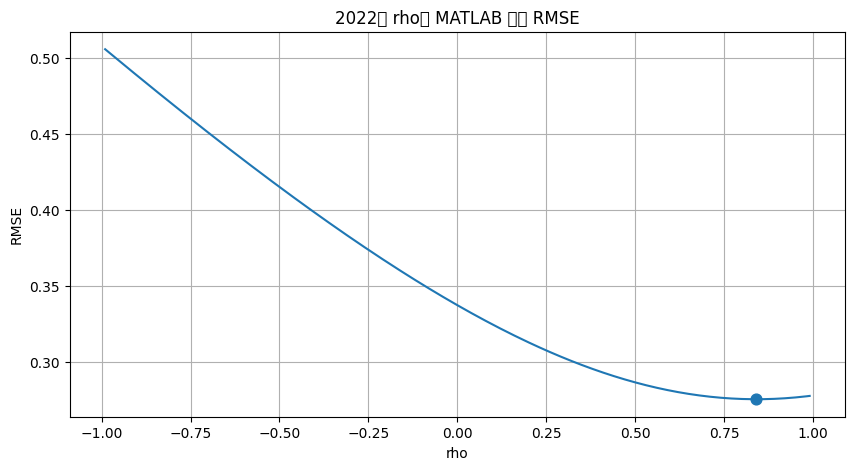

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49885 (\N{HANGUL SYLLABLE SIG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


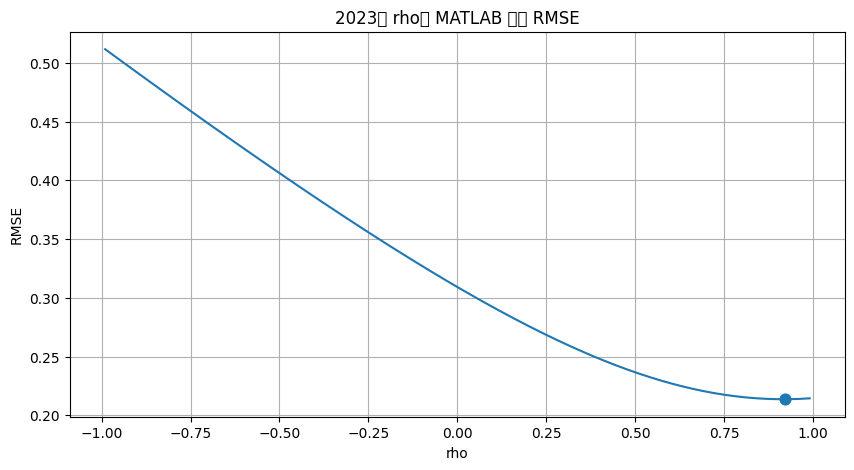

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49885 (\N{HANGUL SYLLABLE SIG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


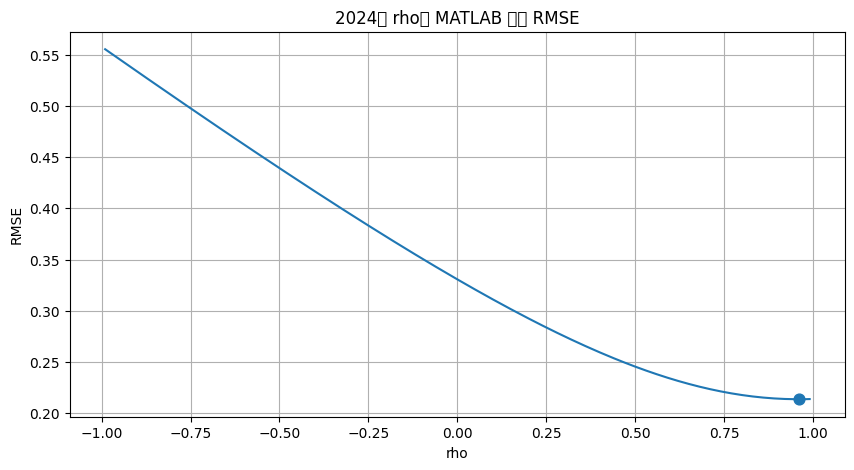

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49885 (\N{HANGUL SYLLABLE SIG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


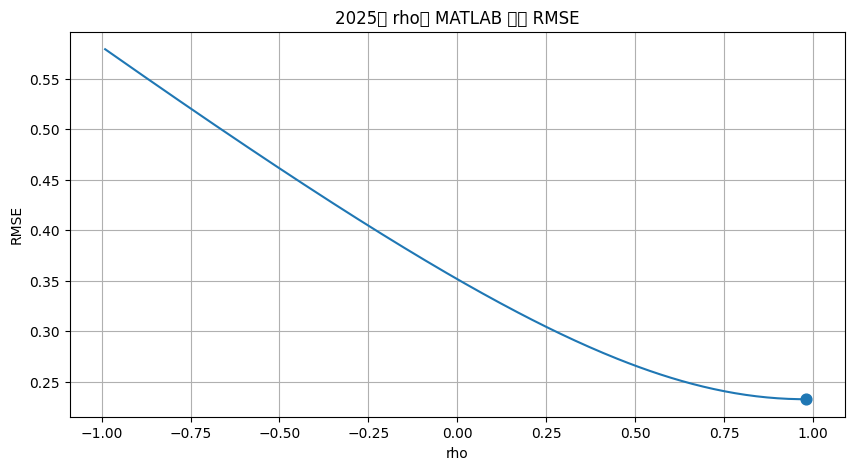

In [ ]:
for year in YEARS:
    if year not in year_results:
        continue

    rho_df = year_results[year]["rho_search_df"]
    best_rho = year_results[year]["best_rho"]
    best_rmse = year_results[year]["best_rmse"]

    ax = rho_df.plot(
        x="rho",
        y="RMSE",
        figsize=(10, 5),
        grid=True,
        title=f"{year}년 rho별 MATLAB 방식 RMSE",
        legend=False,
    )

    ax.scatter([best_rho], [best_rmse], s=60, zorder=3)
    ax.set_xlabel("rho")
    ax.set_ylabel("RMSE")

    plt.show()


## MATLAB 원본과의 대응 관계

| MATLAB `Code.m` | 이 노트북 |
|---|---|
| `if no_all<=30000` | `spatial_lag_matlab_branch_small()` |
| `unique(location_data(:,1:2),'rows')` | 좌표별 `groupby(..., sort=True)` |
| 중복 좌표 가격 `mean(rep_price)` | 좌표별 `Mean_Price` |
| `[d1km d2km]=lldistkm(...)` | 동일 Haversine 식 |
| `d1km<=distance_band` | `d1km <= DISTANCE_BAND_KM` |
| `spwmat(i,j)=1/d1km` | `1.0 / d1km` |
| `spwmat./sumrow` | 각 행의 가중치를 행 합으로 나눔 |
| `spwmat_rowsum*DD1_uni` | 유일좌표 평균가격에 표준화 W 적용 |
| `else` 대용량 분기 | `spatial_lag_matlab_branch_large()` |
| `i==j || d1km==0` | 자기행 또는 `d1km==0` 제외 |
| `IND_spw(i)=spwmat_rowsum*Y` | 표준화 한 행과 원래 Y의 내적 |
| `Y-rho*IND_spw` | 동일 |
| `fitlm(tbl)` | 상수항 포함 `statsmodels.OLS` |
| `lm.RMSE` | `sqrt(model.mse_resid)` |
| `diag(inv(corrcoef(X)))` | 동일 계산 |

### 저장 구조

- `2022/`
- `2023/`
- `2024/`
- `2025/`
- `yearly_model_summary.csv`
- `yearly_all_results.xlsx`

`no_all > 30000` 분기에서는 MATLAB 원본과 같이 전체 W를 저장하지 않고,
각 행의 표준화 가중치로 바로 `IND_spw`를 계산합니다.
